# Model interactions with tensor-product smooths

When the effect of one predictor changes with another, separate smooths may leave systematic residual structure. We will fit a main-effects model, add a tensor interaction, and examine both the interaction contribution and the complete predicted surface.

## Generate a response with a known interaction

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from nampy.gam import GAM

rng=np.random.default_rng(105)
data=pd.DataFrame(rng.uniform(-1,1,(800,2)),columns=["x","z"])
def truth(x,z):
    return np.sin(3*x)+.5*z+2*x*z

data["y"]=truth(data.x,data.z)+rng.normal(0,.2,len(data))
development,test=train_test_split(data,test_size=.2,random_state=105)
train,validation=train_test_split(development,test_size=.25,random_state=106)
models={}

## Fit separate main effects

In [2]:
main_formula="y ~ s(x,bs='cr',k=10) + s(z,bs='cr',k=10)"
models["Main effects"]=GAM(formula=main_formula,optimize_smoothing=True,smoothing_method="reml").fit(train)

## Inspect residual structure

The validation residuals are colored at their observed x,z positions. Opposite corners show the joint pattern left after fitting separate smooths.

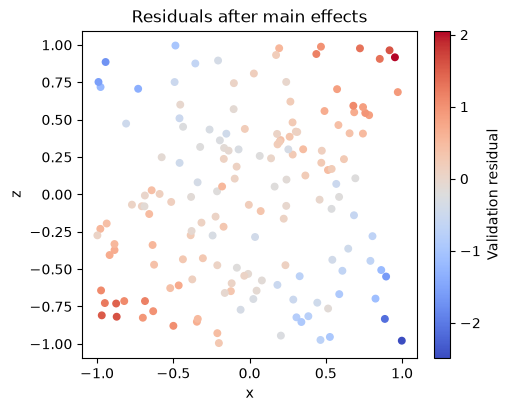

In [3]:
figure,axis=plt.subplots(figsize=(5,4),constrained_layout=True)
image=axis.scatter(validation.x,validation.z,c=validation.y-models["Main effects"].predict(validation),cmap="coolwarm",s=22)
figure.colorbar(image,ax=axis,label="Validation residual")
axis.set(xlabel="x",ylabel="z",title="Residuals after main effects")
plt.show()
plt.close(figure)

## Add ti(x, z)

The tensor interaction excludes the marginal function spaces represented by the main effects. It describes additional joint variation.

In the `s(x) + s(z) + ti(x,z)` formula, the marginal smooths represent main effects; the constrained `ti` term adds the remaining joint contribution. A `te` or `t2` term alone represents a joint surface including marginal structure, so its displayed contribution is not directly interchangeable with this interaction-only term.

In [4]:
models["Main effects plus ti"]=GAM(formula=main_formula+" + ti(x,z,bs=c('cr','cr'),k=c(8,8))",optimize_smoothing=True,smoothing_method="reml").fit(train)

## Inspect the interaction and total surface

The interaction contribution is the additional joint pattern beyond the fitted lower-order effects. The total predicted surface includes those effects and the intercept. Plotting both avoids mistaking an interaction component for the complete response relationship.

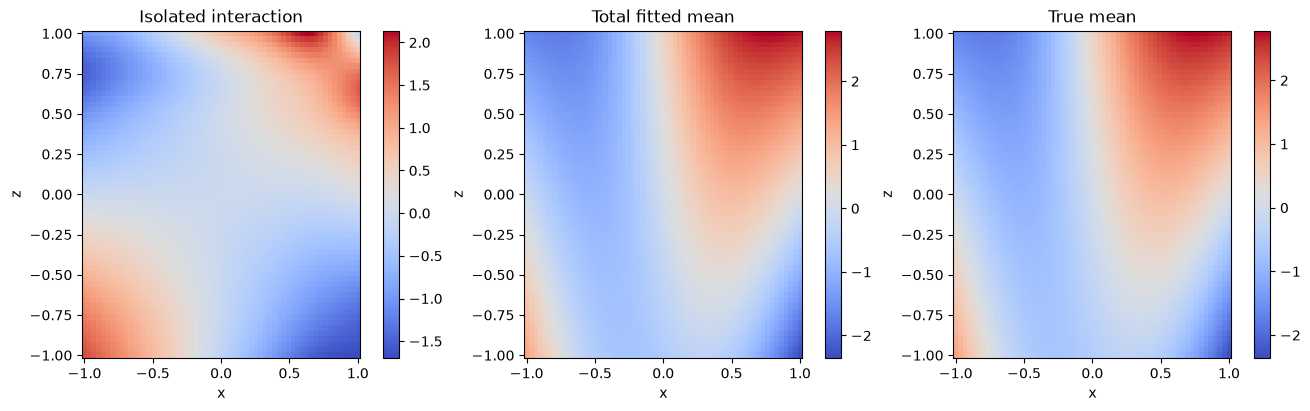

In [5]:
values=np.linspace(-1,1,60)
gx,gz=np.meshgrid(values,values)
grid=pd.DataFrame({"x":gx.ravel(),"z":gz.ravel()})
model=models["Main effects plus ti"]
result=model.fit_result()
matrix=model.lpmatrix(grid)
interaction=np.zeros(len(grid))
for term in result.term_results:
    if term.label.startswith("ti("):
        start,stop=term.coef_slice
        interaction+=matrix[:,start:stop]@result.coef_full[start:stop]
figure,axes=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
for axis,surface,title in zip(axes,[interaction,model.predict(grid),truth(grid.x,grid.z)],["Isolated interaction","Total fitted mean","True mean"]):
    image=axis.pcolormesh(gx,gz,np.asarray(surface).reshape(gx.shape),shading="auto",cmap="coolwarm")
    figure.colorbar(image,ax=axis)
    axis.set(title=title,xlabel="x",ylabel="z")
plt.show()
plt.close(figure)

## Compare with a full tensor smooth

A `te` term models the complete surface in one block, including marginal structure. We compare its predictions rather than treating its contribution as the same estimand as `ti`. The compact [formula reference](../user_guide/formula_visual_reference.rst) also illustrates `t2` penalty decomposition.

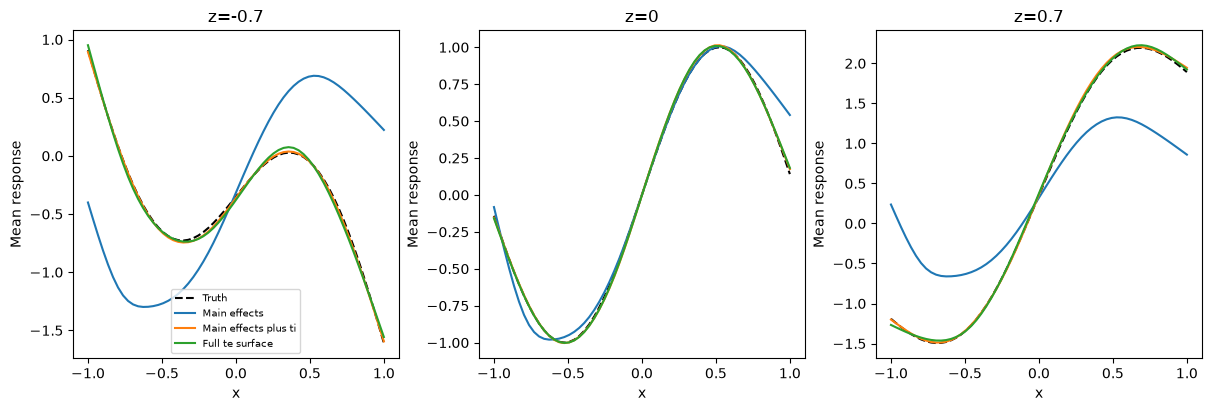

Model,Test RMSE
Main effects,0.743
Main effects plus ti,0.192
Full te surface,0.193


In [6]:
models["Full te surface"]=GAM(formula="y ~ te(x,z,bs=c('cr','cr'),k=c(8,8))",optimize_smoothing=True,smoothing_method="reml").fit(train)
figure,axes=plt.subplots(1,3,figsize=(12,4),constrained_layout=True)
for axis,z in zip(axes,[-.7,0,.7]):
    probe=pd.DataFrame({"x":values,"z":z})
    axis.plot(values,truth(values,z),"k--",label="Truth")
    for name,model in models.items():
        axis.plot(values,model.predict(probe),label=name)
    axis.set(title=f"z={z:g}",xlabel="x",ylabel="Mean response")
axes[0].legend(fontsize=7)
plt.show()
plt.close(figure)
pd.DataFrame([{"Model":name,"Test RMSE":mean_squared_error(test.y,model.predict(test))**.5} for name,model in models.items()]).style.hide(axis="index").format({"Test RMSE":"{:.3f}"})

The main-effects fit has test RMSE 0.743; adding the interaction lowers it to 0.192. The full tensor surface gives a similar 0.193. The isolated interaction and full surface remain different quantities despite similar predictive accuracy.